# Evaluasi Model YOLO di Test Set

Pakai `best.pt` (PyTorch) untuk prediksi test set, lalu:
1. Visualisasikan gambar yang error (deteksi meleset)
2. Buat confusion matrix

**Hijau** = label asli (ground truth), **Merah** = prediksi model.

In [3]:
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------- SETTING ----------
MODEL_PATH = "./best.pt"  # ganti ke path best.pt kamu
DATA_ROOT = Path("datasets/number-plate-5f0ee7ed")
IMG_DIR = DATA_ROOT / "images" / "test"
LBL_DIR = DATA_ROOT / "labels" / "test"

CONF = 0.25        # confidence threshold prediksi
IOU_MATCH = 0.5    # IoU minimal agar prediksi dianggap cocok ke GT
MAX_SHOW = 12      # maksimal gambar error yang ditampilkan
# -----------------------------

In [4]:
# Cari lokasi best.pt kalau belum yakin path-nya
found = glob.glob("runs/detect/**/best.pt", recursive=True)
print("best.pt ditemukan di:")
for f in found:
    print(" ", f)

best.pt ditemukan di:


In [5]:
# ---------- helper ----------
def yolo_to_xyxy(box, w, h):
    """Label YOLO (cx,cy,bw,bh ternormalisasi) -> piksel (x1,y1,x2,y2)."""
    cx, cy, bw, bh = box
    return [(cx - bw / 2) * w, (cy - bh / 2) * h,
            (cx + bw / 2) * w, (cy + bh / 2) * h]


def iou(a, b):
    """IoU dua box [x1,y1,x2,y2]."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def load_gt(label_path, w, h):
    """Baca label YOLO -> list box piksel."""
    boxes = []
    if not label_path.exists():
        return boxes
    for line in label_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        _, cx, cy, bw, bh = map(float, parts[:5])
        boxes.append(yolo_to_xyxy((cx, cy, bw, bh), w, h))
    return boxes


def analyze(gt_boxes, pred_boxes):
    """Matching IoU -> (tp, fp, fn)."""
    matched = set()
    tp = fp = 0
    for pb in pred_boxes:
        best_iou, best_j = 0.0, -1
        for j, gb in enumerate(gt_boxes):
            if j in matched:
                continue
            cur = iou(pb, gb)
            if cur > best_iou:
                best_iou, best_j = cur, j
        if best_iou >= IOU_MATCH:
            tp += 1
            matched.add(best_j)
        else:
            fp += 1
    fn = len(gt_boxes) - len(matched)
    return tp, fp, fn

In [6]:
# ---------- prediksi seluruh test set ----------
model = YOLO(MODEL_PATH)

img_paths = sorted(
    glob.glob(str(IMG_DIR / "*.jpg")) + glob.glob(str(IMG_DIR / "*.png"))
)
print(f"Total gambar test: {len(img_paths)}")

total_tp = total_fp = total_fn = 0
error_images = []  # (path, gt, pred, tp, fp, fn)

for p in img_paths:
    img = cv2.imread(p)
    if img is None:
        continue
    h, w = img.shape[:2]

    gt_boxes = load_gt(LBL_DIR / (Path(p).stem + ".txt"), w, h)
    res = model.predict(p, conf=CONF, verbose=False)[0]
    pred_boxes = [b.tolist() for b in res.boxes.xyxy.cpu()]

    tp, fp, fn = analyze(gt_boxes, pred_boxes)
    total_tp += tp
    total_fp += fp
    total_fn += fn
    if fp > 0 or fn > 0:
        error_images.append((p, gt_boxes, pred_boxes, tp, fp, fn))

print(f"TP={total_tp}  FP={total_fp}  FN={total_fn}")
print(f"Gambar dengan error: {len(error_images)} dari {len(img_paths)}")

precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) else 0
recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
print(f"Precision={precision:.3f}  Recall={recall:.3f}  F1={f1:.3f}")

Total gambar test: 882
TP=882  FP=14  FN=20
Gambar dengan error: 24 dari 882
Precision=0.984  Recall=0.978  F1=0.981


## 1. Visualisasi gambar error

Hijau = label asli, Merah = prediksi model.

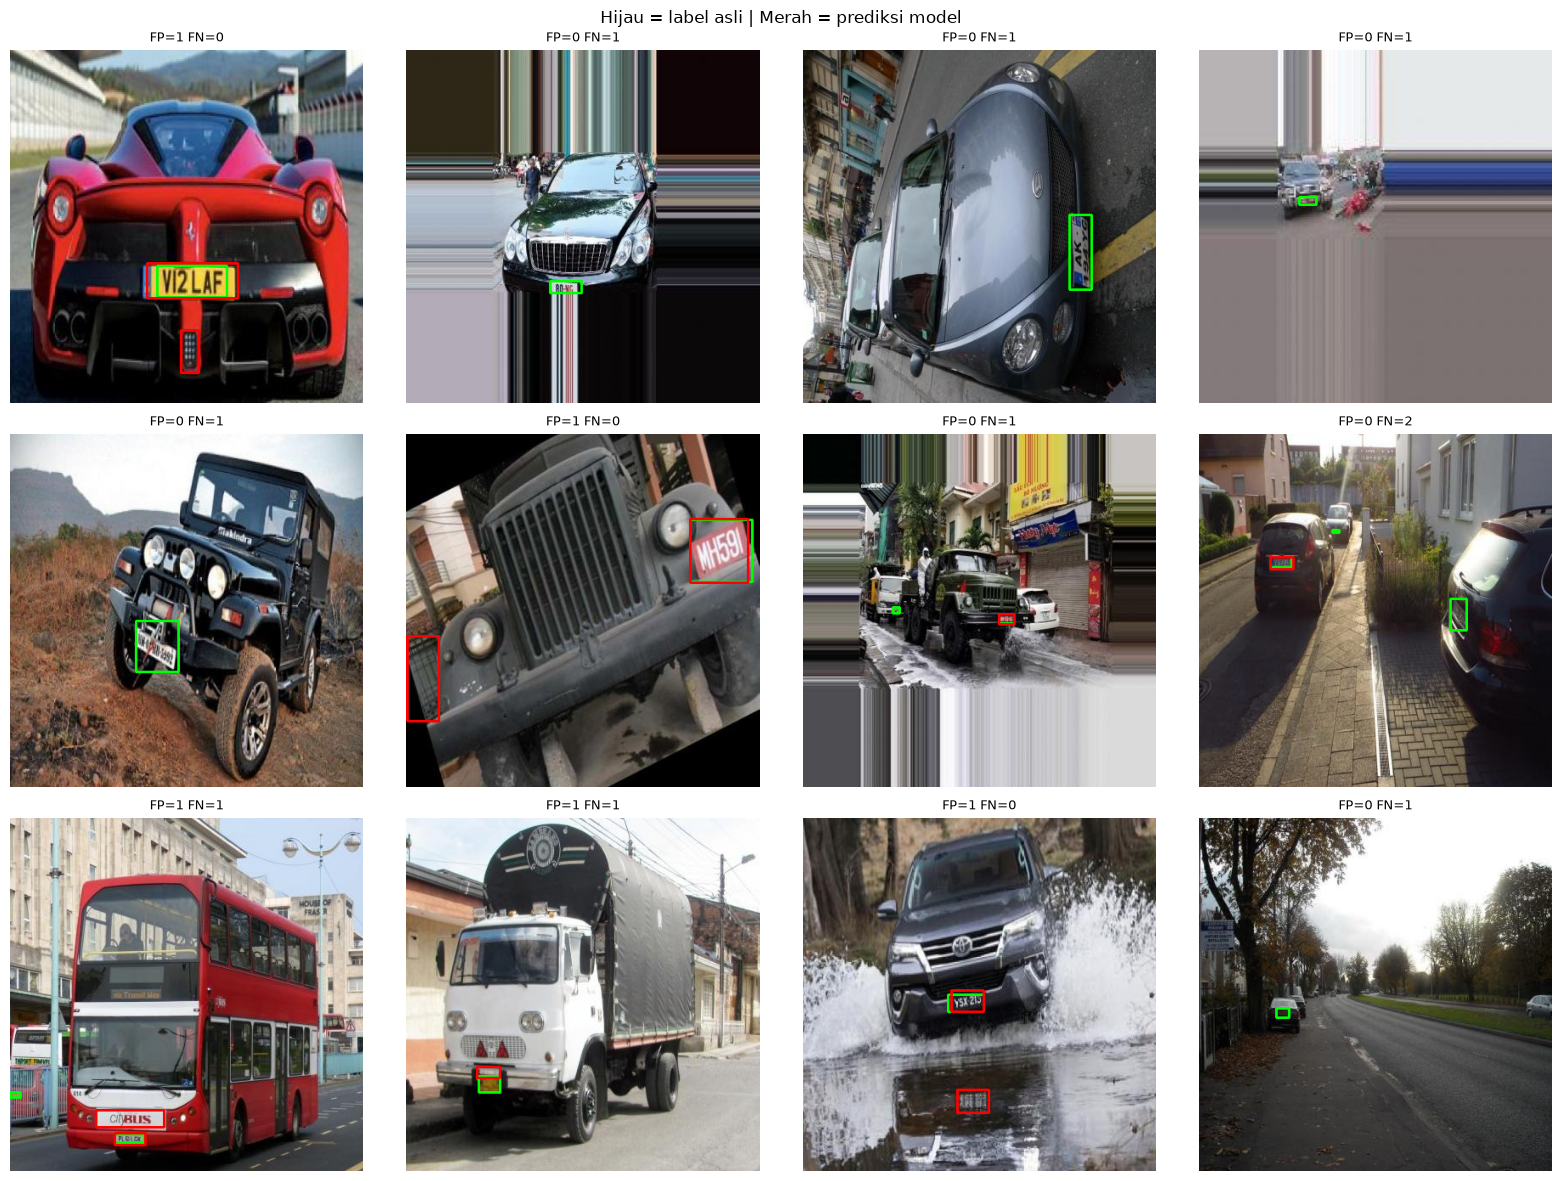

In [7]:
show = error_images[:MAX_SHOW]

if not show:
    print("Tidak ada gambar error.")
else:
    cols = 4
    rows = (len(show) + cols - 1) // cols
    plt.figure(figsize=(cols * 4, rows * 4))

    for i, (p, gt, pred, tp, fp, fn) in enumerate(show):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        for b in gt:
            x1, y1, x2, y2 = map(int, b)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        for b in pred:
            x1, y1, x2, y2 = map(int, b)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(img)
        ax.set_title(f"FP={fp} FN={fn}", fontsize=9)
        ax.axis("off")

    plt.suptitle("Hijau = label asli | Merah = prediksi model", fontsize=12)
    plt.tight_layout()
    plt.show()

## 2. Confusion matrix

Untuk deteksi 1 kelas, confusion matrix dibuat dari pasangan **plate** vs **background**:
- **TP**: plat asli terdeteksi benar
- **FP**: model deteksi plat padahal background (prediksi plate, aktual background)
- **FN**: plat asli ke-miss (prediksi background, aktual plate)
- **TN**: tidak dihitung pada deteksi objek (tidak ada "true negative" yang terdefinisi)

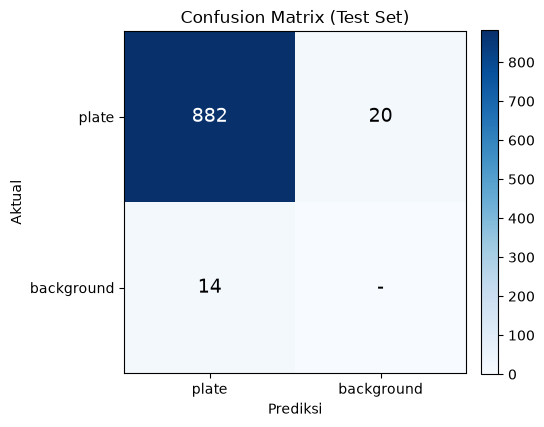

TP (plat benar terdeteksi): 882
FN (plat ke-miss):          20
FP (deteksi salah):         14


In [8]:
# Matriks 2x2: baris = aktual, kolom = prediksi
#            pred plate   pred background
# act plate     TP             FN
# act bg        FP             -
cm = np.array([[total_tp, total_fn],
               [total_fp, 0]])

labels = ["plate", "background"]

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1], labels=labels)
ax.set_yticks([0, 1], labels=labels)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title("Confusion Matrix (Test Set)")

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        # sel kanan-bawah (TN) tidak terdefinisi untuk deteksi
        text = "-" if (i == 1 and j == 1) else str(val)
        color = "white" if val > cm.max() / 2 else "black"
        ax.text(j, i, text, ha="center", va="center", color=color, fontsize=14)

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f"TP (plat benar terdeteksi): {total_tp}")
print(f"FN (plat ke-miss):          {total_fn}")
print(f"FP (deteksi salah):         {total_fp}")